# Employee Attrition Prediction Models
**Classification:** predict `Attrition` using Logistic Regression, Decision Tree, Random Forest, XGBoost.
**Regression (optional):** predict `JobSatisfaction`.
**Evaluation:** Accuracy, Precision, Recall, F1, ROC-AUC. **Improvement:** hyperparameter tuning, cross-validation, feature importance (+ SHAP).

Dataset: IBM HR Analytics Employee Attrition (1470 employees, 35 columns) in `data/`.

In [1]:
import warnings, os, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier, XGBRegressor

RANDOM_STATE = 42
os.makedirs("../outputs", exist_ok=True); os.makedirs("../reports", exist_ok=True)
sns.set_theme(style="whitegrid")

## 1. Load data & EDA

In [2]:
df = pd.read_csv("../data/WA_Fn-UseC_-HR-Employee-Attrition.csv", encoding="utf-8-sig")
print(df.shape); print("Missing values:", df.isna().sum().sum())
df.head()

(1470, 35)
Missing values: 0


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
# Constant / ID columns carry no signal -> drop
const_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns:", const_cols)
df = df.drop(columns=const_cols + ["EmployeeNumber"])
print(df["Attrition"].value_counts(normalize=True).round(3))

Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
Attrition
No     0.839
Yes    0.161
Name: proportion, dtype: float64


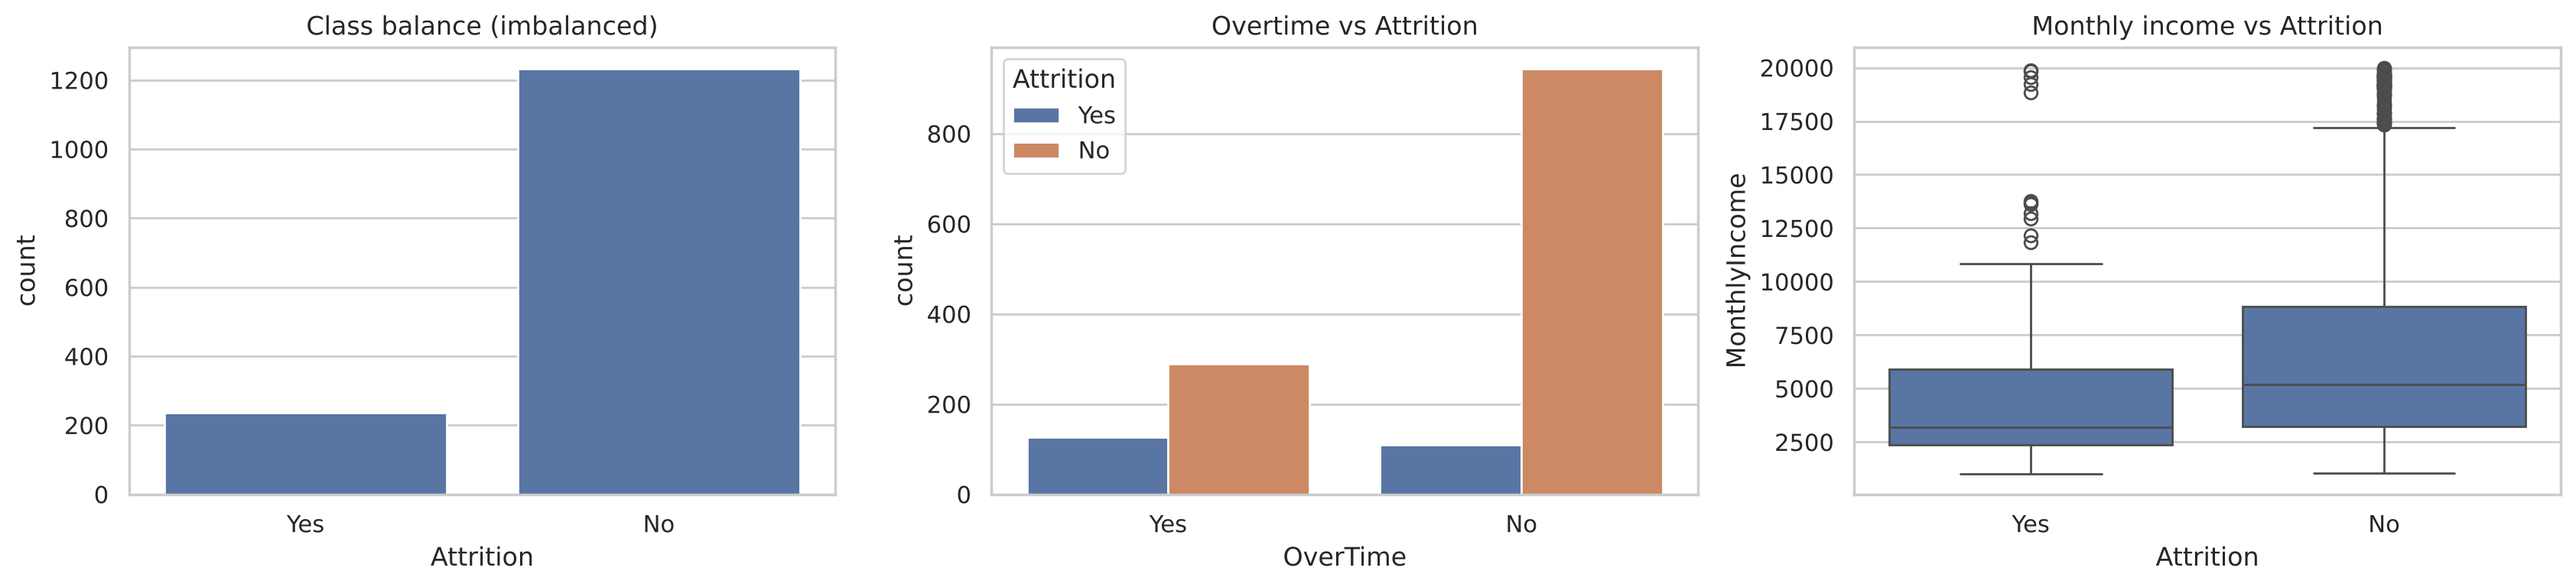

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.countplot(data=df, x="Attrition", ax=ax[0]); ax[0].set_title("Class balance (imbalanced)")
sns.countplot(data=df, x="OverTime", hue="Attrition", ax=ax[1]); ax[1].set_title("Overtime vs Attrition")
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome", ax=ax[2]); ax[2].set_title("Monthly income vs Attrition")
plt.tight_layout(); plt.savefig("../outputs/eda_overview.png", dpi=120); plt.show()

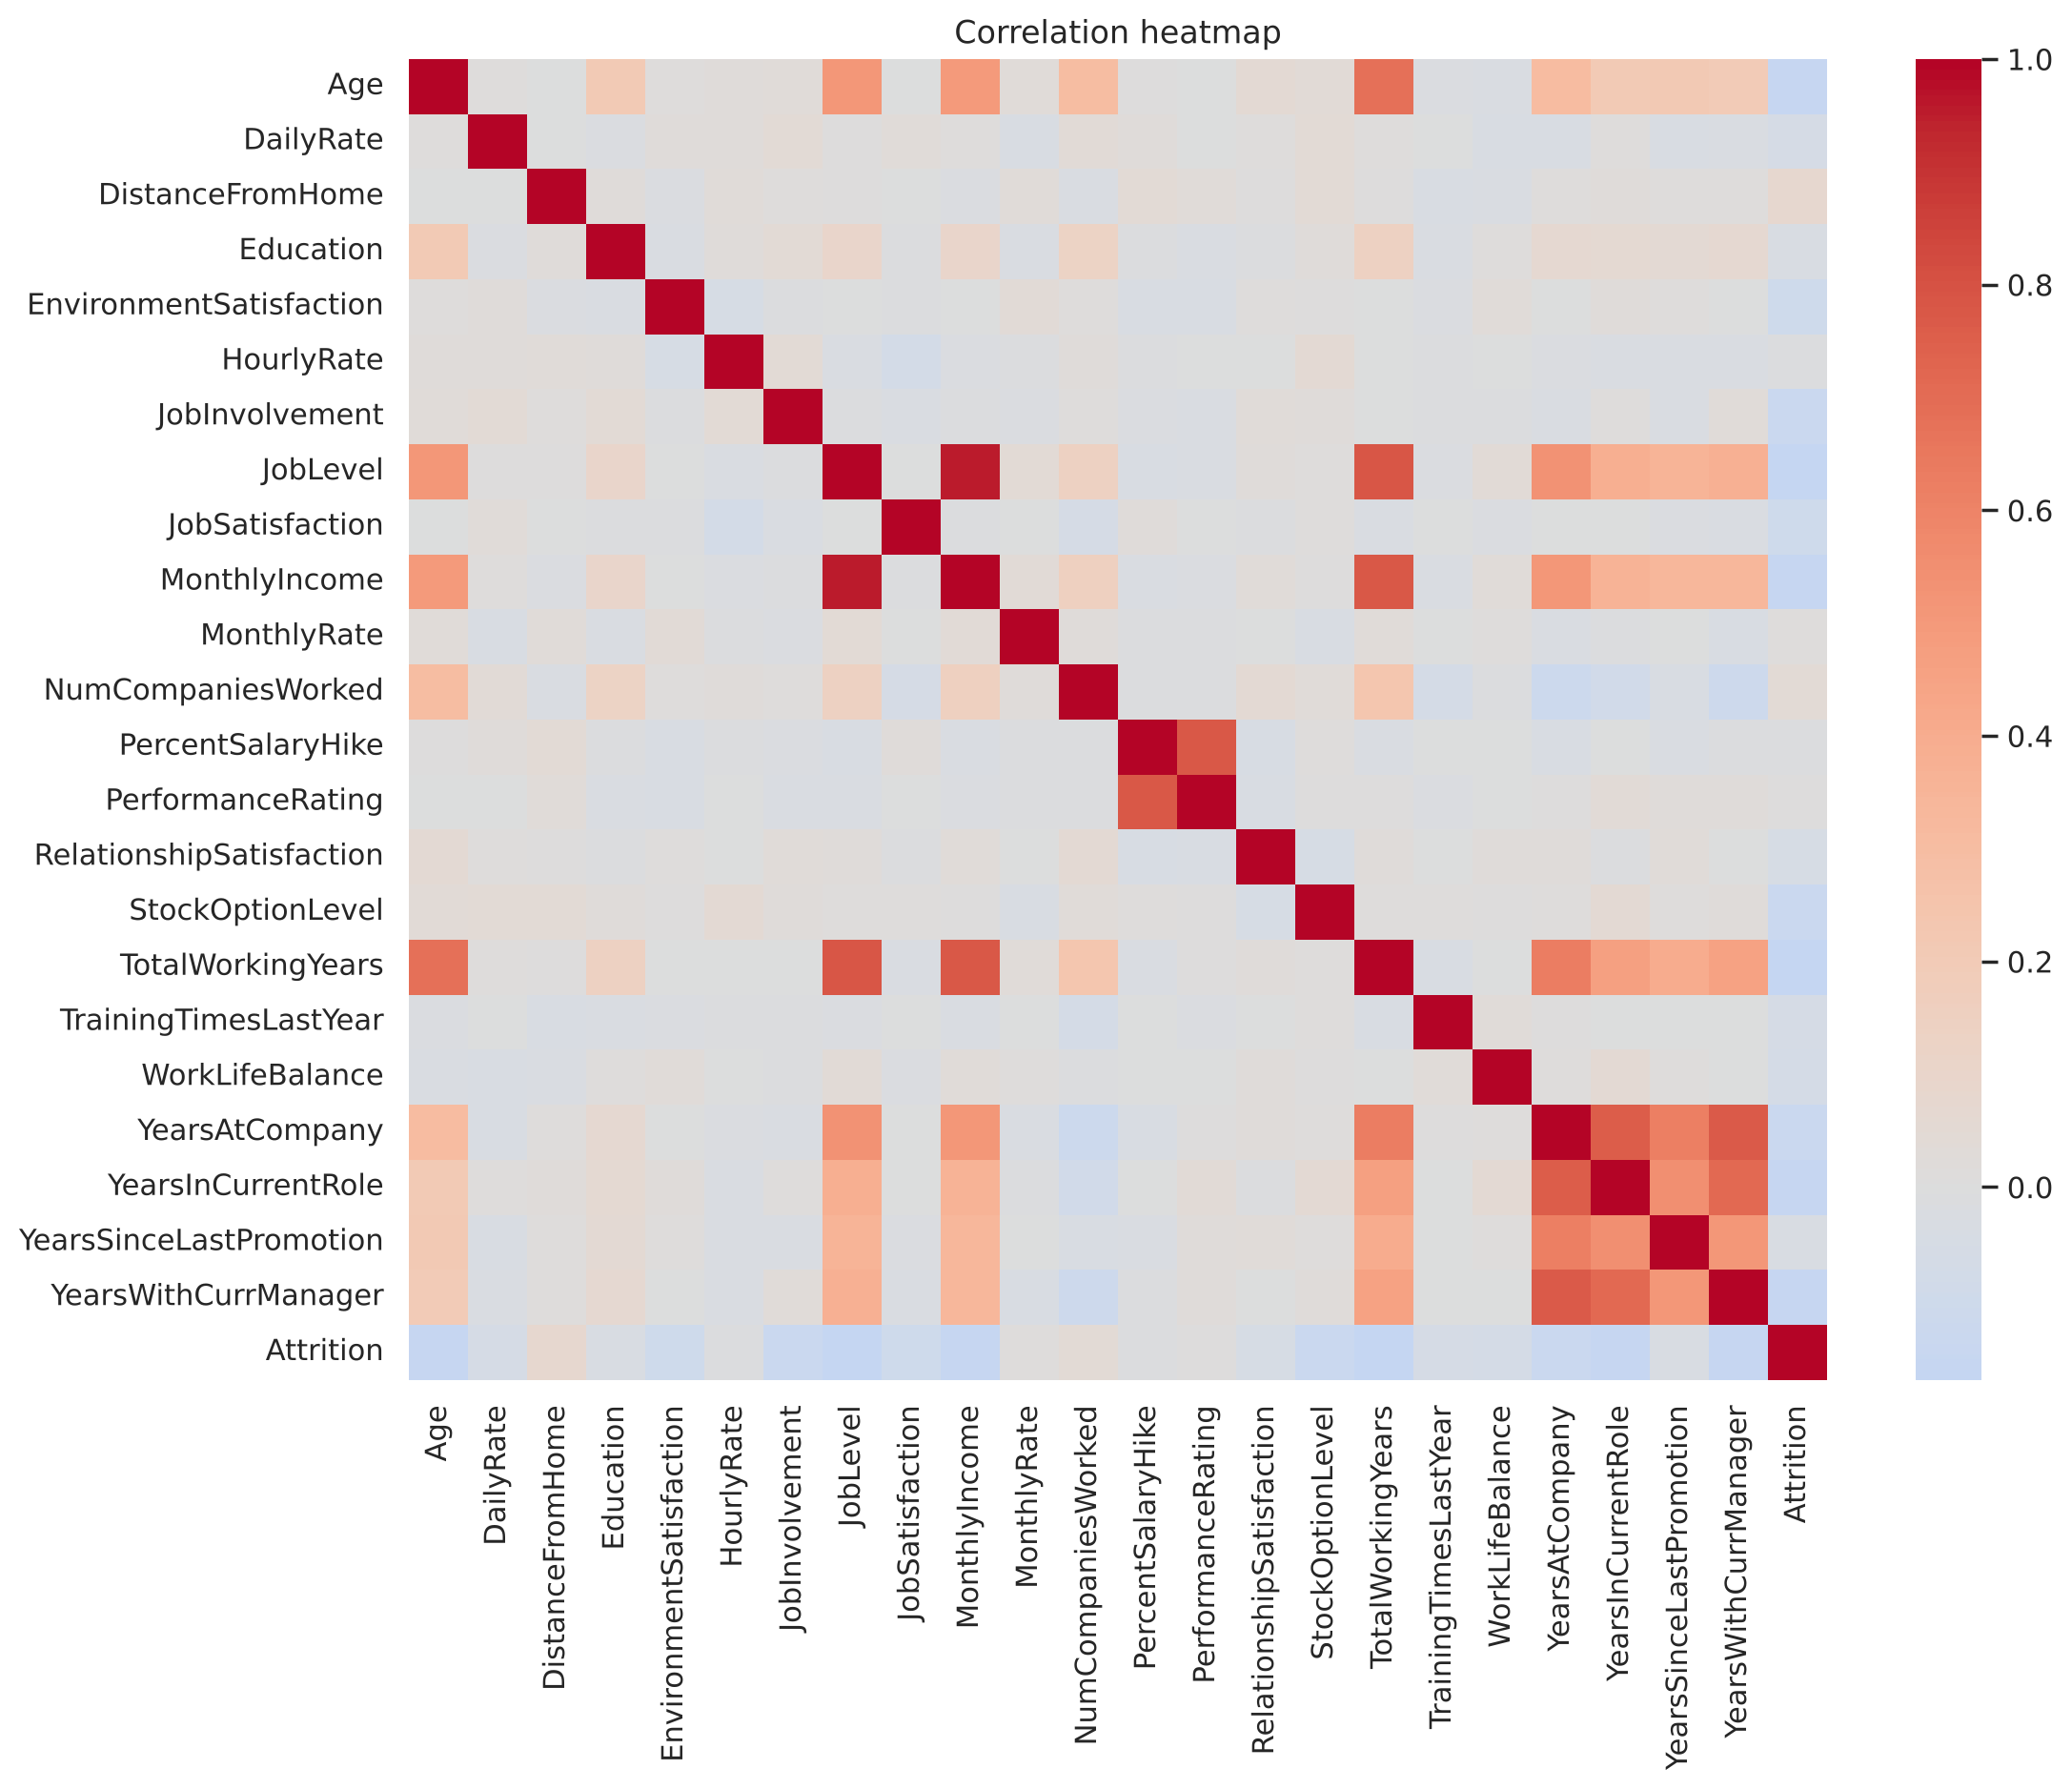

TotalWorkingYears    -0.171
JobLevel             -0.169
YearsInCurrentRole   -0.161
MonthlyIncome        -0.160
Age                  -0.159
Name: Attrition, dtype: float64
HourlyRate           -0.007
PerformanceRating     0.003
MonthlyRate           0.015
NumCompaniesWorked    0.043
DistanceFromHome      0.078
Name: Attrition, dtype: float64


In [5]:
num = df.select_dtypes("number").assign(Attrition=(df.Attrition=="Yes").astype(int))
plt.figure(figsize=(12, 9)); sns.heatmap(num.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation heatmap"); plt.savefig("../outputs/correlation.png", dpi=120, bbox_inches="tight"); plt.show()
print(num.corr()["Attrition"].drop("Attrition").sort_values().round(3).head(5))
print(num.corr()["Attrition"].drop("Attrition").sort_values().round(3).tail(5))

## 2. Preprocessing & train/test split (stratified)
One-hot encode categoricals, scale numerics (needed for Logistic Regression; harmless for trees). All steps sit inside a `Pipeline`, so scaling is fit **only on training folds** (no data leakage).

In [6]:
y = (df["Attrition"] == "Yes").astype(int)
X = df.drop(columns="Attrition")
cat_cols = X.select_dtypes("object").columns.tolist()
num_cols = X.select_dtypes("number").columns.tolist()

def make_pre():
    return ColumnTransformer([("num", StandardScaler(), num_cols),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
spw = (y_train == 0).sum() / (y_train == 1).sum()   # for XGBoost imbalance handling
print(X_train.shape, X_test.shape, "scale_pos_weight =", round(spw, 2))

(1176, 30) (294, 30) scale_pos_weight = 5.19


## 3. Baseline models (class imbalance handled via class weights) + 5-fold stratified CV

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree":       DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost":             XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
}
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

def evaluate(name, pipe, tag):
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test); proba = pipe.predict_proba(X_test)[:, 1]
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=skf, scoring="roc_auc", n_jobs=-1)
    return dict(Model=name, Stage=tag, Accuracy=accuracy_score(y_test, pred), Precision=precision_score(y_test, pred, zero_division=0),
                Recall=recall_score(y_test, pred), F1=f1_score(y_test, pred), ROC_AUC=roc_auc_score(y_test, proba),
                CV_AUC_mean=cv_auc.mean(), CV_AUC_std=cv_auc.std())

rows, fitted = [], {}
for n, m in models.items():
    p = Pipeline([("pre", make_pre()), ("clf", m)])
    rows.append(evaluate(n, p, "Baseline")); fitted[(n, "Baseline")] = p
base = pd.DataFrame(rows); base.round(3)

,Model,Stage,Accuracy,Precision,Recall,F1,ROC_AUC,CV_AUC_mean,CV_AUC_std
0,Logistic Regression,Baseline,0.752,0.349,0.638,0.451,0.803,0.827,0.028
1,Decision Tree,Baseline,0.779,0.304,0.298,0.301,0.584,0.582,0.024
2,Random Forest,Baseline,0.837,0.485,0.340,0.400,0.791,0.810,0.038
3,XGBoost,Baseline,0.854,0.583,0.298,0.394,0.776,0.802,0.041


## 4. Hyperparameter tuning (cross-validated search, optimising ROC-AUC)

In [8]:
grids = {
 "Logistic Regression": (GridSearchCV, {"clf__C": [0.01, 0.1, 1, 10], "clf__penalty": ["l2"]}),
 "Decision Tree": (GridSearchCV, {"clf__max_depth": [3, 4, 5, 7, 10], "clf__min_samples_leaf": [5, 10, 20], "clf__criterion": ["gini", "entropy"]}),
 "Random Forest": (RandomizedSearchCV, {"clf__n_estimators": [200, 400, 600], "clf__max_depth": [4, 6, 8, 12, None],
                                        "clf__min_samples_leaf": [1, 3, 5, 10], "clf__max_features": ["sqrt", 0.3, 0.5]}),
 "XGBoost": (RandomizedSearchCV, {"clf__n_estimators": [100, 200, 400], "clf__max_depth": [2, 3, 4, 6],
                                  "clf__learning_rate": [0.01, 0.03, 0.05, 0.1], "clf__subsample": [0.7, 0.85, 1.0],
                                  "clf__colsample_bytree": [0.6, 0.8, 1.0]}),
}
rows, best_params = [], {}
for n, (Searcher, grid) in grids.items():
    pipe = Pipeline([("pre", make_pre()), ("clf", models[n])])
    kw = dict(n_iter=20, random_state=RANDOM_STATE) if Searcher is RandomizedSearchCV else {}
    gs = Searcher(pipe, grid, cv=skf, scoring="roc_auc", n_jobs=-1, **kw).fit(X_train, y_train)
    best_params[n] = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
    fitted[(n, "Tuned")] = gs.best_estimator_
    rows.append(evaluate(n, gs.best_estimator_, "Tuned"))
    print(n, "->", best_params[n])
tuned = pd.DataFrame(rows)
results = pd.concat([base, tuned]).sort_values(["Model", "Stage"]).reset_index(drop=True)
results.round(3).to_csv("../outputs/classification_results.csv", index=False)
results.round(3)

Logistic Regression -> {'C': 0.1, 'penalty': 'l2'}


Decision Tree -> {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 10}


Random Forest -> {'n_estimators': 400, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}


XGBoost -> {'subsample': 0.7, 'n_estimators': 200, 'max_depth': 2, 'learning_rate': 0.05, 'colsample_bytree': 0.6}


,Model,Stage,Accuracy,Precision,Recall,F1,ROC_AUC,CV_AUC_mean,CV_AUC_std
0,Decision Tree,Baseline,0.779,0.304,0.298,0.301,0.584,0.582,0.024
1,Decision Tree,Tuned,0.731,0.289,0.468,0.358,0.677,0.733,0.036
2,Logistic Regression,Baseline,0.752,0.349,0.638,0.451,0.803,0.827,0.028
3,Logistic Regression,Tuned,0.772,0.381,0.681,0.489,0.812,0.831,0.029
4,Random Forest,Baseline,0.837,0.485,0.340,0.400,0.791,0.810,0.038
5,Random Forest,Tuned,0.837,0.485,0.340,0.400,0.797,0.811,0.034
6,XGBoost,Baseline,0.854,0.583,0.298,0.394,0.776,0.802,0.041
7,XGBoost,Tuned,0.786,0.389,0.596,0.471,0.789,0.829,0.025


## 5. Evaluation: ROC curves, confusion matrices

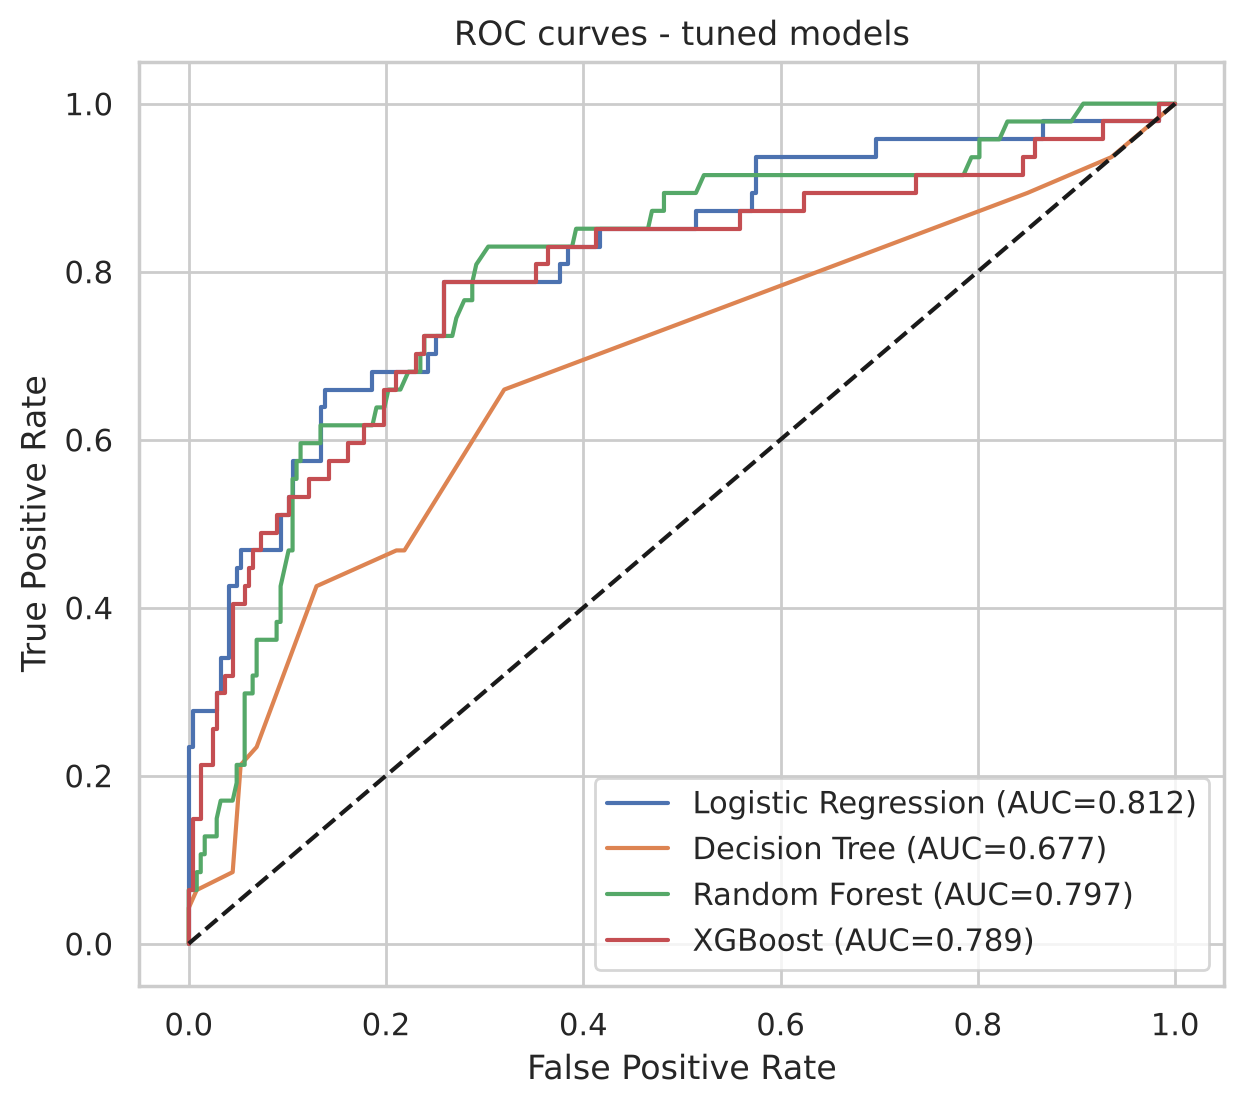

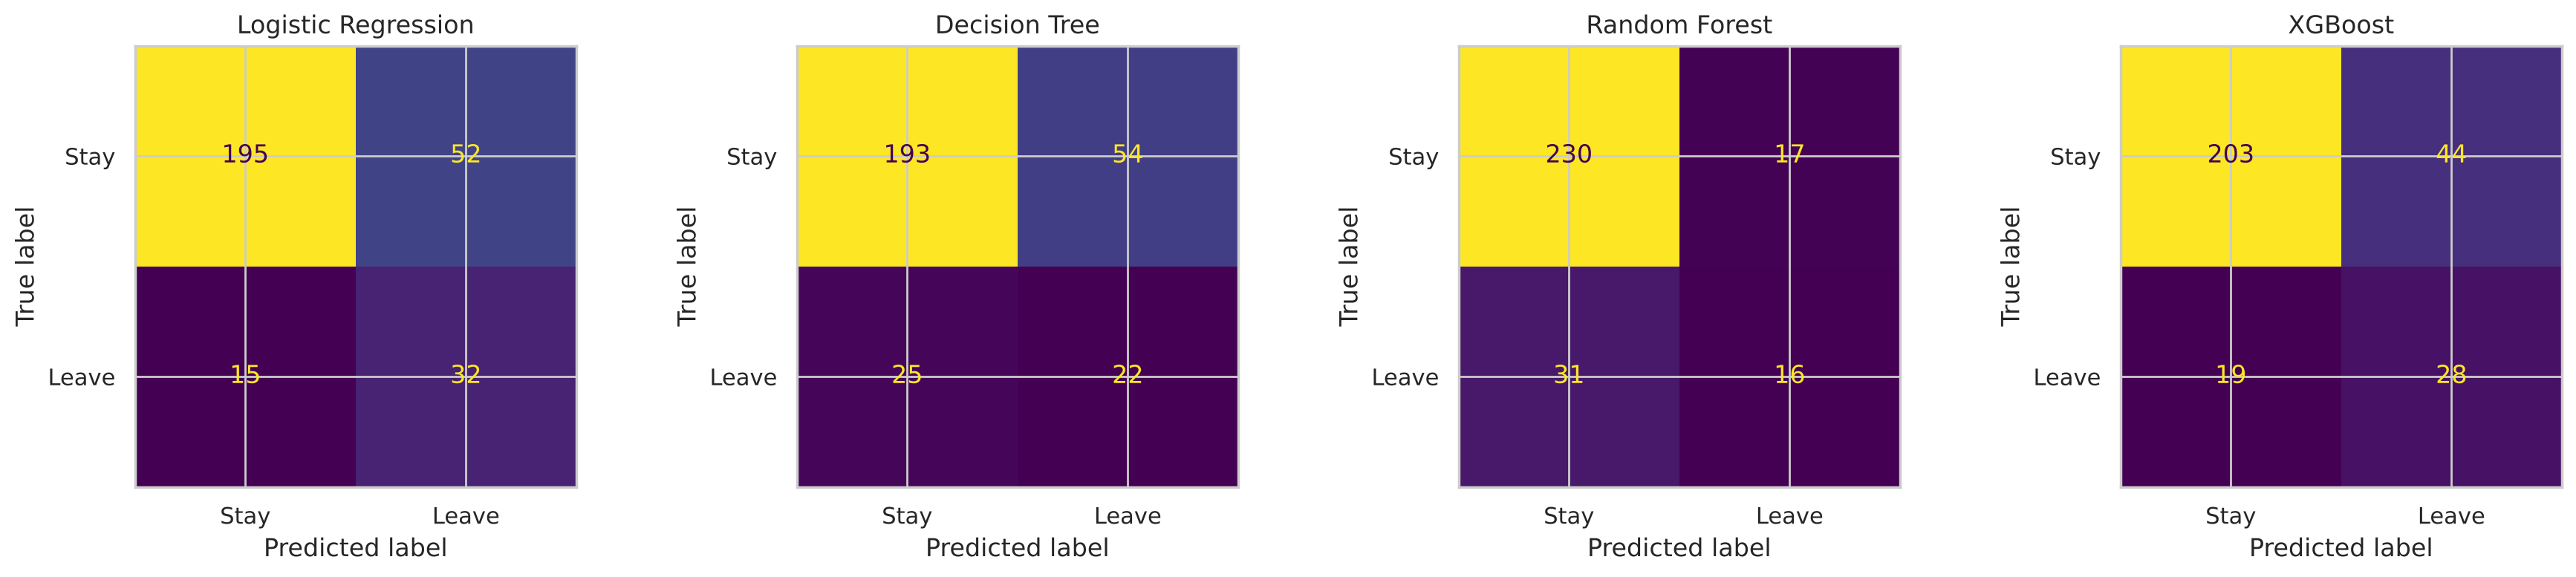

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
for n in models:
    p = fitted[(n, "Tuned")]; fpr, tpr, _ = roc_curve(y_test, p.predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_test, p.predict_proba(X_test)[:,1]):.3f})")
ax.plot([0, 1], [0, 1], "k--"); ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves - tuned models"); ax.legend(); plt.savefig("../outputs/roc_curves.png", dpi=120); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for a, n in zip(axes, models):
    ConfusionMatrixDisplay.from_estimator(fitted[(n, "Tuned")], X_test, y_test, ax=a, colorbar=False, display_labels=["Stay", "Leave"])
    a.set_title(n)
plt.tight_layout(); plt.savefig("../outputs/confusion_matrices.png", dpi=120); plt.show()

## 6. Choose the final model
Attrition is imbalanced, so accuracy is misleading. We rank by **ROC-AUC** (threshold-free) and look at **Recall / F1** for the Leave class, since missing a leaver costs more than a wasted retention conversation.

In [10]:
tuned_sorted = tuned.sort_values("ROC_AUC", ascending=False)
best_name = tuned_sorted.iloc[0]["Model"]; best_pipe = fitted[(best_name, "Tuned")]
print("Best tuned model by ROC-AUC:", best_name)
tuned_sorted.round(3)

Best tuned model by ROC-AUC: Logistic Regression


,Model,Stage,Accuracy,Precision,Recall,F1,ROC_AUC,CV_AUC_mean,CV_AUC_std
0,Logistic Regression,Tuned,0.772,0.381,0.681,0.489,0.812,0.831,0.029
2,Random Forest,Tuned,0.837,0.485,0.340,0.400,0.797,0.811,0.034
3,XGBoost,Tuned,0.786,0.389,0.596,0.471,0.789,0.829,0.025
1,Decision Tree,Tuned,0.731,0.289,0.468,0.358,0.677,0.733,0.036


In [11]:
# Threshold analysis: trade precision for recall
proba = best_pipe.predict_proba(X_test)[:, 1]
thr = pd.DataFrame([{"Threshold": t, "Precision": precision_score(y_test, proba>=t, zero_division=0),
                     "Recall": recall_score(y_test, proba>=t), "F1": f1_score(y_test, proba>=t)} for t in np.arange(0.1, 0.8, 0.1)])
thr.round(3)

,Threshold,Precision,Recall,F1
0,0.1,0.185,0.957,0.310
1,0.2,0.223,0.936,0.361
2,0.3,0.274,0.851,0.415
3,0.4,0.325,0.787,0.460
4,0.5,0.381,0.681,0.489
5,0.6,0.466,0.574,0.514
6,0.7,0.564,0.468,0.512


## 7. Feature importance
Model-native importance + permutation importance (model-agnostic, computed on the test set).

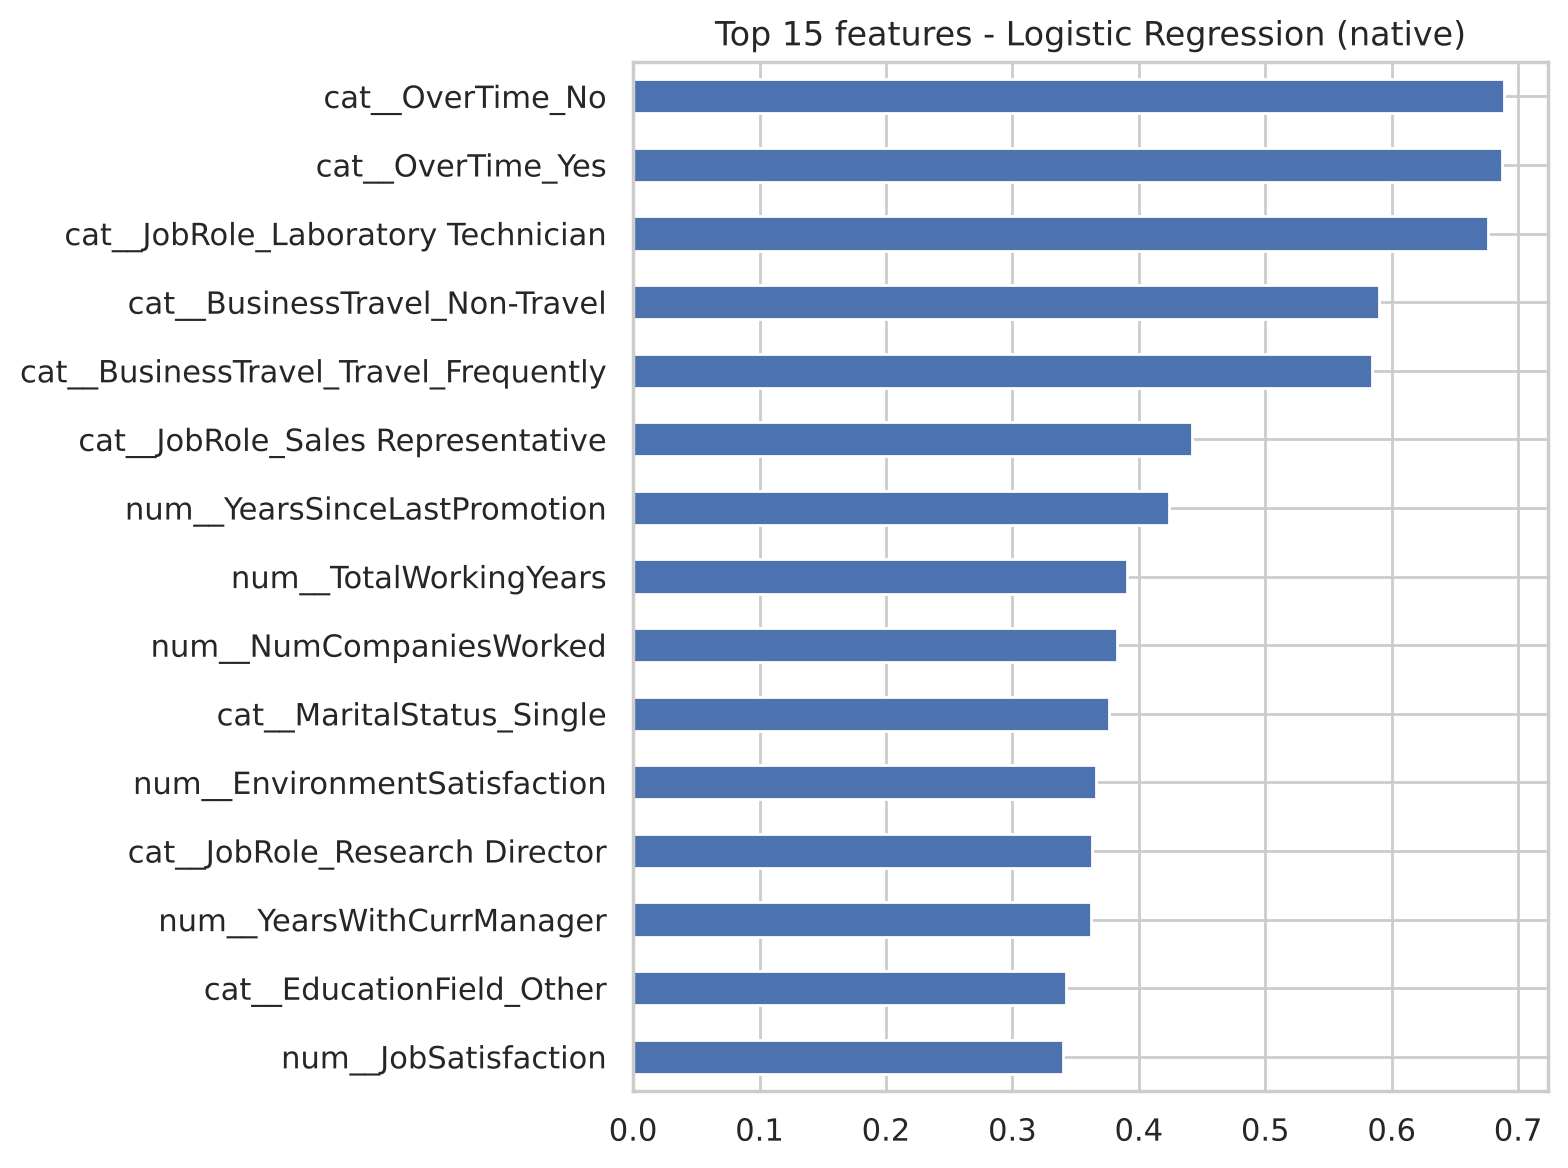

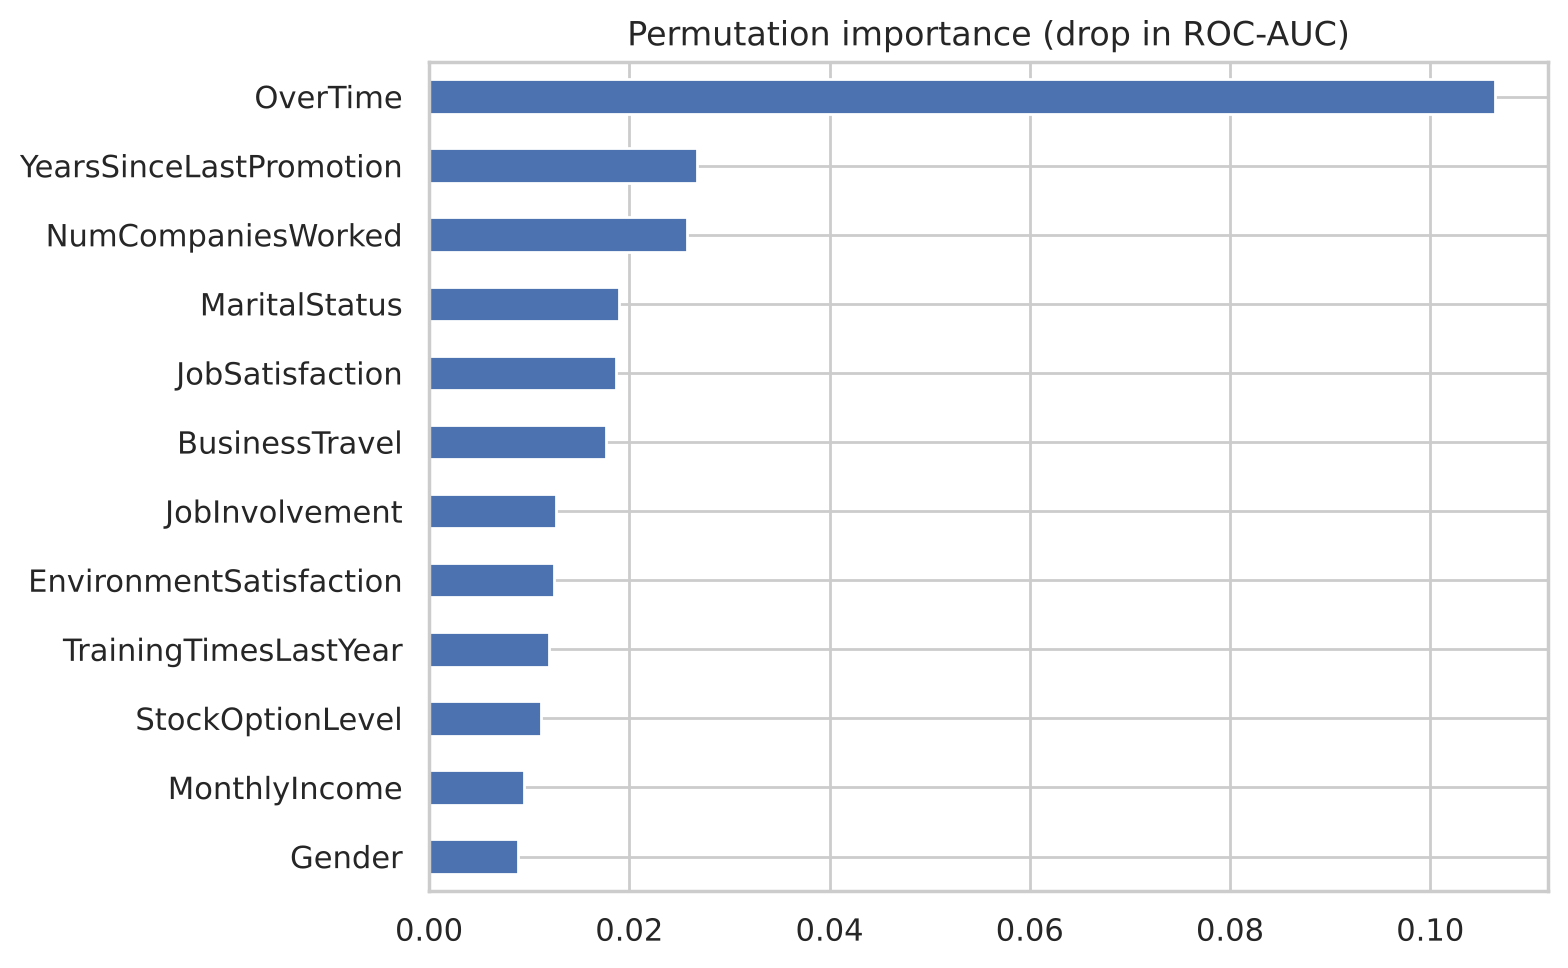

OverTime                   0.1064
YearsSinceLastPromotion    0.0267
NumCompaniesWorked         0.0257
MaritalStatus              0.0189
JobSatisfaction            0.0187
BusinessTravel             0.0177
JobInvolvement             0.0127
EnvironmentSatisfaction    0.0125
TrainingTimesLastYear      0.0120
StockOptionLevel           0.0111
MonthlyIncome              0.0095
Gender                     0.0089
dtype: float64

In [12]:
feat_names = best_pipe.named_steps["pre"].get_feature_names_out()
clf = best_pipe.named_steps["clf"]
if hasattr(clf, "feature_importances_"):
    imp = pd.Series(clf.feature_importances_, index=feat_names)
else:
    imp = pd.Series(np.abs(clf.coef_[0]), index=feat_names)
imp = imp.sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 6)); imp[::-1].plot.barh(); plt.title(f"Top 15 features - {best_name} (native)")
plt.tight_layout(); plt.savefig("../outputs/feature_importance.png", dpi=120); plt.show()

perm = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc", n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False).head(12)
plt.figure(figsize=(8, 5)); perm_s[::-1].plot.barh(); plt.title("Permutation importance (drop in ROC-AUC)")
plt.tight_layout(); plt.savefig("../outputs/permutation_importance.png", dpi=120); plt.show()
perm_s.round(4)

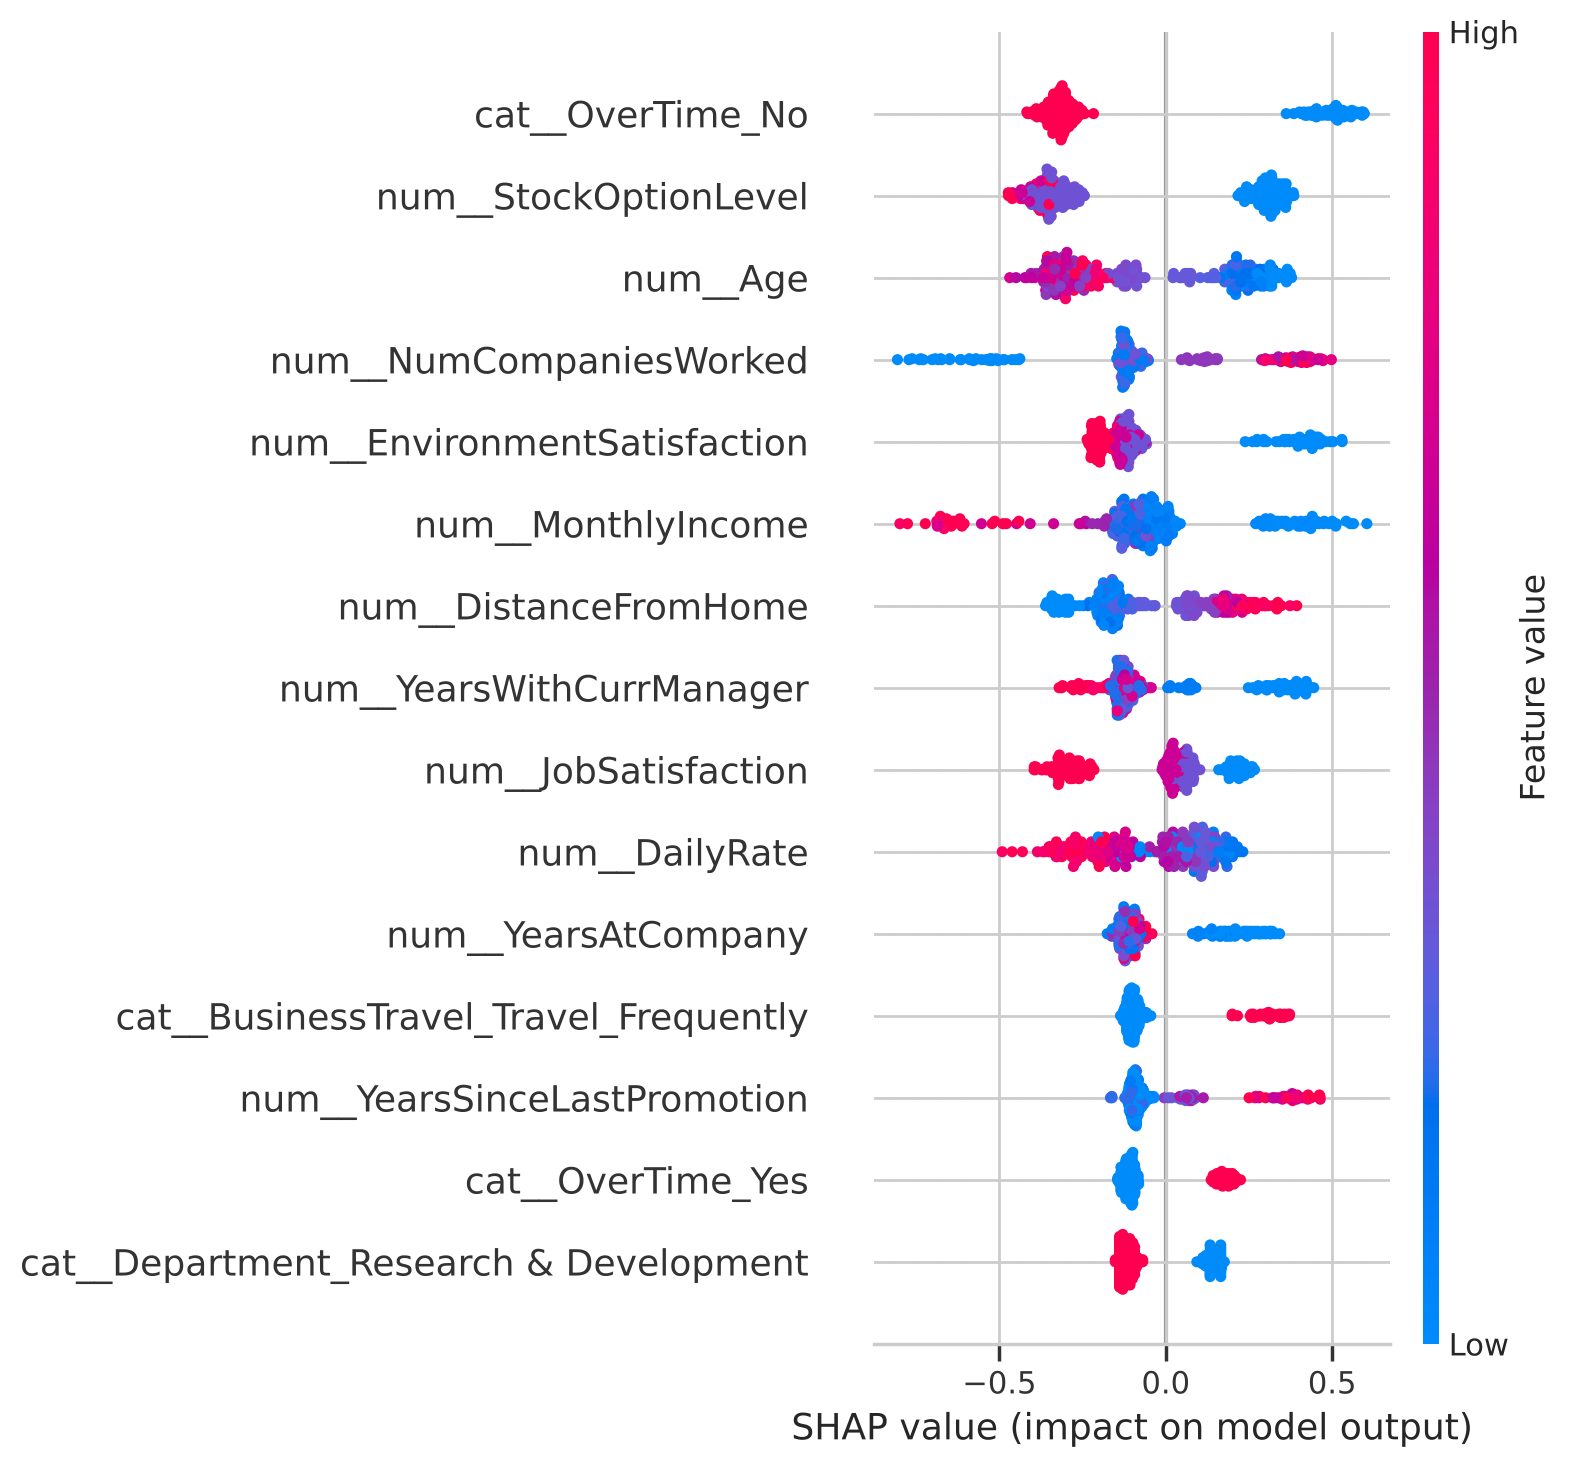

In [13]:
# SHAP (explainability) - best tree model if available, else XGBoost
import shap
shap_name = best_name if best_name in ("Random Forest", "XGBoost") else "XGBoost"
sp = fitted[(shap_name, "Tuned")]
Xt = sp.named_steps["pre"].transform(X_test); Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
expl = shap.TreeExplainer(sp.named_steps["clf"]); sv = expl.shap_values(Xt)
if isinstance(sv, list): sv = sv[1]
elif getattr(sv, "ndim", 2) == 3: sv = sv[:, :, 1]
shap.summary_plot(sv, Xt, feature_names=feat_names, show=False, max_display=15)
plt.tight_layout(); plt.savefig("../outputs/shap_summary.png", dpi=120, bbox_inches="tight"); plt.show()

## 8. Regression (optional business task): predict `JobSatisfaction` (1-4)
`PerformanceRating` only takes values 3/4 and overtime is only Yes/No in this dataset, so JobSatisfaction is the most suitable regression target. Attrition is excluded from the features.

In [14]:
yr = df["JobSatisfaction"]; Xr = df.drop(columns=["JobSatisfaction", "Attrition"])
cat_r = Xr.select_dtypes("object").columns.tolist(); num_r = Xr.select_dtypes("number").columns.tolist()
pre_r = lambda: ColumnTransformer([("num", StandardScaler(), num_r), ("cat", OneHotEncoder(handle_unknown="ignore"), cat_r)])
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=RANDOM_STATE)
reg_models = {"Linear Regression": LinearRegression(), "Ridge": Ridge(alpha=10),
              "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
              "XGBoost": XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=RANDOM_STATE)}
kf = KFold(5, shuffle=True, random_state=RANDOM_STATE); rrows = []
for n, m in reg_models.items():
    p = Pipeline([("pre", pre_r()), ("reg", m)]).fit(Xr_tr, yr_tr); pr = p.predict(Xr_te)
    cv = cross_val_score(p, Xr_tr, yr_tr, cv=kf, scoring="r2", n_jobs=-1)
    rrows.append(dict(Model=n, MAE=mean_absolute_error(yr_te, pr), RMSE=np.sqrt(mean_squared_error(yr_te, pr)), R2=r2_score(yr_te, pr), CV_R2=cv.mean()))
reg_results = pd.DataFrame(rrows); reg_results.round(3).to_csv("../outputs/regression_results.csv", index=False); reg_results.round(3)

,Model,MAE,RMSE,R2,CV_R2
0,Linear Regression,0.975,1.155,-0.054,-0.056
1,Ridge,0.973,1.151,-0.049,-0.049
2,Random Forest,0.969,1.138,-0.025,-0.042
3,XGBoost,0.987,1.162,-0.069,-0.105


In [15]:
print("Baseline (always predict the mean) MAE:", round(mean_absolute_error(yr_te, np.full(len(yr_te), yr_tr.mean())), 3))

Baseline (always predict the mean) MAE: 0.97


**Interpretation:** R² is about 0 (slightly negative) for every model and MAE is no better than predicting the mean. In this dataset JobSatisfaction is essentially unrelated to the other columns, so it cannot be predicted reliably. This is an honest negative result: report it, and note that satisfaction is better measured by surveys than inferred from HR records.

## 9. Auto-generate the Evaluation Report and Business Interpretation Report

In [16]:
b = tuned_sorted.iloc[0]
cm = confusion_matrix(y_test, best_pipe.predict(X_test)); tn, fp, fn, tp = cm.ravel()
top_feats = ", ".join(perm_s.index[:6])
def table(d): return d.round(3).to_markdown(index=False)

eval_report = f'''# Evaluation Report - Employee Attrition Prediction

## 1. Data & method
- IBM HR Analytics dataset, {len(df)} employees, {X.shape[1]} usable features; attrition rate {y.mean():.1%} (imbalanced).
- Stratified 80/20 train/test split (random_state={RANDOM_STATE}); preprocessing inside a Pipeline to avoid leakage.
- Imbalance handled with class weights (`balanced`) and XGBoost `scale_pos_weight` = {spw:.2f}.
- Tuning: GridSearchCV / RandomizedSearchCV, 5-fold stratified CV, scoring = ROC-AUC.

## 2. Classification results (test set; CV = 5-fold on train)
{table(results)}

Best tuned model by ROC-AUC: **{best_name}** (AUC {b.ROC_AUC:.3f}, Recall {b.Recall:.3f}, Precision {b.Precision:.3f}, F1 {b.F1:.3f}).
Best hyperparameters: `{best_params[best_name]}`.

Confusion matrix of the best model: TN={tn}, FP={fp}, FN={fn}, TP={tp}.

## 3. Threshold analysis ({best_name})
{table(thr)}

## 4. Feature importance
Top drivers (permutation importance): {top_feats}.
Figures: `outputs/roc_curves.png`, `confusion_matrices.png`, `feature_importance.png`, `permutation_importance.png`, `shap_summary.png`.

## 5. Regression (optional): JobSatisfaction
{table(reg_results)}

## 6. Limitations
- Only {len(X_test)} test rows ({int(y_test.sum())} leavers), so metrics vary by split; CV std is reported.
- The dataset is a fictional IBM sample; results may not transfer to a real company.
- JobSatisfaction is ordinal (1-4); regression is a simplification.
'''
open("../reports/evaluation_report.md", "w").write(eval_report)

biz_report = f'''# Business Interpretation Report - Employee Attrition

## Key message
About {y.mean():.0%} of employees leave. The final model ({best_name}) ranks employees by leaving risk with ROC-AUC {b.ROC_AUC:.2f}.
At the default threshold it catches {b.Recall:.0%} of actual leavers ({tp} of {tp+fn} in the test set), but only {b.Precision:.0%} of employees it flags actually leave
({fp} false alarms), so it is best used to **prioritise conversations**, not to make automatic decisions.

## What drives attrition (permutation importance)
Most influential features: {top_feats}.
Read these alongside the EDA charts (`outputs/eda_overview.png`) and SHAP plot (`outputs/shap_summary.png`) to see the direction of each effect
(for example, whether overtime or low income push risk up).

## Recommended actions (verify against the SHAP/EDA direction before presenting)
1. Review overtime policy and workload for high-risk groups.
2. Check pay competitiveness and promotion gaps for low-income / long-time-in-role employees.
3. Run stay interviews with the top-risk decile each quarter.
4. Prefer a lower threshold (higher recall) if retention conversations are cheap; raise it if HR capacity is limited (see threshold table).

## Cost trade-off
A missed leaver (false negative) costs recruiting + training + lost productivity; a false alarm costs one manager conversation. Because FN cost >> FP cost, recall is prioritised over precision.

## Ethics & caution
Do not use Gender, Age or MaritalStatus to take adverse action; audit for bias. Use predictions to offer support, not to penalise employees.
'''
open("../reports/business_interpretation_report.md", "w").write(biz_report)
print("Reports written to ../reports")

Reports written to ../reports
